# Base de datos de facturas: limpieza para entrenar

Este cuaderno toma el Excel de Microsoft Forms y las fotos, y deja una tabla limpia con solo 5 columnas: foto, monto (con centavos si los trae), fecha, categoría y motivo. Endereza las fotos que quedaron de lado, marca las de baja resolución y mide el ancho, alto, píxeles y peso de cada imagen (info_imagenes.csv). Si alguna factura la subieron como PDF, la convierte sola a imagen.

**Antes de empezar, ten a la mano dos archivos:**
1. El Excel de Forms guardado como `.xlsx`.
2. El zip con las fotos (o PDFs), descargado desde OneDrive (Mis archivos > Aplicaciones > Microsoft Forms > tu formulario > la carpeta de la pregunta de la foto).

Ejecuta las celdas en orden. En la segunda celda te pide subir los dos archivos.

Los correos y nombres de tus compañeros no pasan a la tabla final.

In [ ]:
!pip -q install pillow-heif openpyxl pypdfium2 pytesseract
!apt-get -qq install -y tesseract-ocr > /dev/null 2>&1
import os, re, io, base64, shutil, zipfile
from urllib.parse import unquote
import pandas as pd
from PIL import Image, ImageOps
import pypdfium2 as pdfium
from IPython.display import HTML, display
from google.colab import files
try:
    import pillow_heif
    pillow_heif.register_heif_opener()
except Exception:
    pass

In [ ]:
# Sube el Excel (.xlsx) y el zip de las fotos
subidos = files.upload()
xlsx_path = next((n for n in subidos if n.lower().endswith(".xlsx")), None)
zip_paths = [n for n in subidos if n.lower().endswith(".zip")]   # puedes subir las fotos en varios zips
assert xlsx_path and zip_paths, "Falta subir el Excel (.xlsx) o el zip de las fotos"
print("Excel:", xlsx_path)
print("Zips de fotos:", ", ".join(zip_paths))

Saving OneDrive_2026-11-10.zip to OneDrive_2026-11-10.zip
Saving Registro de Facturas ACTUALIZADO.xlsx to Registro de Facturas ACTUALIZADO (1).xlsx
Excel: Registro de Facturas ACTUALIZADO (1).xlsx
Zips de fotos: OneDrive_2026-11-10.zip


In [ ]:
import unicodedata

CATEGORIAS = ["Supermercado", "Restaurantes y domicilios", "Transporte", "Servicios", "Salud",
              "Educación", "Entretenimiento", "Hogar", "Ropa y accesorios", "Otros"]

def norm(s):
    s = unicodedata.normalize("NFD", str(s))
    return "".join(ch for ch in s if unicodedata.category(ch) != "Mn").lower().strip()

MAPA_CAT = {norm(c): c for c in CATEGORIAS}

# 1) Leer el Excel y ubicar las 5 columnas que sirven
df = pd.read_excel(xlsx_path)

def col(clave):
    for c in df.columns:
        if clave in str(c).upper():
            return c
    raise KeyError(f"No encontré la columna que contiene '{clave}'")

c_foto, c_monto, c_fecha = col("FOTO"), col("MONTO"), col("FECHA")
c_cat, c_motivo = col("CATEGOR"), col("MOTIVO")

# 2) Descomprimir las fotos y hacer un índice por nombre de archivo
shutil.rmtree("fotos_originales", ignore_errors=True)
for zp in zip_paths:
    with zipfile.ZipFile(zp) as z:
        z.extractall("fotos_originales")
indice = {}
for raiz, _, archivos in os.walk("fotos_originales"):
    for a in archivos:
        indice[a.lower()] = os.path.join(raiz, a)

def a_monto(v):
    """Devuelve el monto como número con hasta 2 decimales (ej. 103976.62).
    Si llega texto, interpreta puntos y comas: 2 dígitos tras el último
    separador son centavos; 3 dígitos son miles."""
    if isinstance(v, (int, float)) and not pd.isna(v):
        return round(float(v), 2)
    s = re.sub(r"[^\d.,]", "", str(v))
    if not re.search(r"\d", s):
        return None
    if "." in s and "," in s:
        dec = "." if s.rfind(".") > s.rfind(",") else ","
    elif "." in s or "," in s:
        sep = "." if "." in s else ","
        ultimo = s.split(sep)[-1]
        dec = sep if (s.count(sep) == 1 and len(ultimo) in (1, 2)) else None
    else:
        dec = None
    if dec:
        ent, _, frac = s.rpartition(dec)
        ent = re.sub(r"\D", "", ent)
        return round(float(f"{ent or 0}.{re.sub(chr(92) + 'D', '', frac)}"), 2)
    return float(re.sub(r"\D", "", s))

# Convierte un PDF a imágenes (una por página, máximo 2) con buena resolución para OCR
def pdf_a_imagenes(ruta_pdf, prefijo, k_inicial, maximo):
    nombres = []
    pdf = pdfium.PdfDocument(ruta_pdf)
    if len(pdf) > maximo:
        avisos.append(f"{prefijo}: el PDF tiene {len(pdf)} páginas, solo se usan las primeras {maximo}")
    for p in range(min(len(pdf), maximo)):
        img = pdf[p].render(scale=2.8).to_pil().convert("RGB")  # unos 200 DPI
        img.thumbnail((3000, 3000))
        nuevo = f"{prefijo}_{k_inicial + p}.jpg"
        img.save(os.path.join("dataset/imagenes", nuevo), quality=92)
        nombres.append(nuevo)
    return nombres

# 3) Armar el dataset limpio, una fila por factura (máximo 2 fotos cada una)
EXT = r"\.(?:jpe?g|png|heic|heif|webp|pdf)"
shutil.rmtree("dataset", ignore_errors=True)
os.makedirs("dataset/imagenes")
filas, avisos = [], []

for i, r in df.reset_index(drop=True).iterrows():
    n = i + 1
    celda = str(r[c_foto])
    urls = re.findall(r"https?://[^\s;\"']+?" + EXT, celda, flags=re.I)
    if not urls:
        urls = re.findall(r"[^\s;/\"']+?" + EXT, celda, flags=re.I)
    urls = list(dict.fromkeys(urls))
    if len(urls) > 2:
        avisos.append(f"Fila {n}: tiene {len(urls)} fotos, revisa si son más de 2")

    nombres = []
    for u in urls:
        original = unquote(u.split("/")[-1])
        ruta = indice.get(original.lower())
        if not ruta:
            avisos.append(f"Fila {n}: no encontré el archivo '{original}' en el zip")
            continue
        k = len(nombres) + 1
        if k > 2:
            break
        if ruta.lower().endswith(".pdf"):
            nombres += pdf_a_imagenes(ruta, f"factura_{n:03d}", k, 2 - len(nombres))
        else:
            nuevo = f"factura_{n:03d}_{k}{os.path.splitext(ruta)[1].lower()}"
            shutil.copy(ruta, os.path.join("dataset/imagenes", nuevo))
            nombres.append(nuevo)
    if not nombres:
        avisos.append(f"Fila {n}: sin foto, no se incluye en el dataset")
        continue

    monto = a_monto(r[c_monto])
    fecha = pd.to_datetime(r[c_fecha], errors="coerce", dayfirst=True)
    fecha = fecha.strftime("%Y-%m-%d") if pd.notna(fecha) else None
    crudo = re.sub(r"\s*\(.*?\)", "", str(r[c_cat])).strip()
    categoria = MAPA_CAT.get(norm(crudo))
    if categoria is None:
        avisos.append(f"Fila {n}: la categoría '{crudo}' no está en la lista oficial, se cambió a 'Otros'")
        categoria = "Otros"
    motivo = str(r[c_motivo]).strip()
    if monto is None:
        avisos.append(f"Fila {n}: el monto no se pudo leer")
    if fecha is None:
        avisos.append(f"Fila {n}: la fecha no se pudo leer")

    filas.append({"foto": ";".join(nombres), "monto_cop": monto, "fecha": fecha,
                  "categoria": categoria, "motivo": motivo})

tabla = pd.DataFrame(filas)
# Aviso de montos que se ven demasiado altos (por si alguien escribió mal los separadores)
mediana = tabla["monto_cop"].median()
for idx, m in tabla["monto_cop"].items():
    if pd.notna(m) and (m > 5_000_000 or (len(tabla) >= 5 and m > 20 * mediana)):
        avisos.append(f"Factura {idx + 1}: el monto {m:,.2f} se ve muy alto, revisa que no tenga mal los puntos o comas")
print(f"Facturas en el dataset: {len(tabla)} de {len(df)} filas del Excel")
for a in avisos:
    print("AVISO:", a)

Facturas en el dataset: 143 de 143 filas del Excel
AVISO: factura_069: el PDF tiene 3 páginas, solo se usan las primeras 2
AVISO: Factura 80: el monto 1,700,000.00 se ve muy alto, revisa que no tenga mal los puntos o comas
AVISO: Factura 84: el monto 1,700,000.00 se ve muy alto, revisa que no tenga mal los puntos o comas
AVISO: Factura 86: el monto 1,700,000.00 se ve muy alto, revisa que no tenga mal los puntos o comas
AVISO: Factura 88: el monto 1,700,000.00 se ve muy alto, revisa que no tenga mal los puntos o comas
AVISO: Factura 90: el monto 1,700,000.00 se ve muy alto, revisa que no tenga mal los puntos o comas
AVISO: Factura 95: el monto 1,285,200.00 se ve muy alto, revisa que no tenga mal los puntos o comas
AVISO: Factura 96: el monto 2,310,990.00 se ve muy alto, revisa que no tenga mal los puntos o comas
AVISO: Factura 97: el monto 5,794,600.00 se ve muy alto, revisa que no tenga mal los puntos o comas
AVISO: Factura 100: el monto 5,794,600.00 se ve muy alto, revisa que no tenga

In [ ]:
# Enderezar fotos: aplica la rotación del celular y corrige las que tienen el texto de lado o al revés
ENDEREZAR = True   # pon False si no quieres que corrija la orientación automáticamente

try:
    import pytesseract
    from pytesseract import Output
    OCR_OK = True
except Exception:
    OCR_OK = False

def palabras_claras(img):
    g = img.convert("L")
    g.thumbnail((1400, 1400))
    d = pytesseract.image_to_data(g, lang="eng", config="--psm 6", output_type=Output.DICT)
    return sum(1 for t, c in zip(d["text"], d["conf"]) if len(t.strip()) >= 3 and float(c) > 70)

def angulo_correcto(img):
    """Grados (antihorario) que hay que girar la imagen para que el texto quede derecho."""
    base = palabras_claras(img)
    if base >= 15:          # ya se lee bien tal cual
        return 0
    puntajes = {a: palabras_claras(img.rotate(a, expand=True)) for a in (90, 180, 270)}
    mejor = max(puntajes, key=puntajes.get)
    if puntajes[mejor] >= 8 and puntajes[mejor] >= 2 * max(base, 1):
        return mejor
    return 0

rotadas_exif, rotadas_auto, renombres = [], [], {}
for nombre in sorted(os.listdir("dataset/imagenes")):
    ruta = os.path.join("dataset/imagenes", nombre)
    base, ext = os.path.splitext(nombre)
    ext = ext.lower()
    with Image.open(ruta) as im:
        im.load()
        giro_exif = im.getexif().get(274, 1) not in (None, 1)   # el celular guardó la foto rotada
        img = ImageOps.exif_transpose(im) if giro_exif else im.copy()
    angulo = 0
    if ENDEREZAR and OCR_OK:
        try:
            angulo = angulo_correcto(img)
        except Exception:
            angulo = 0
        if angulo:
            img = img.rotate(angulo, expand=True)
    convertir = ext in (".heic", ".heif")      # los HEIC se pasan a JPG para que todo sea compatible
    if giro_exif or angulo or convertir:
        destino = base + ".jpg" if convertir else nombre
        ruta_destino = os.path.join("dataset/imagenes", destino)
        if destino.lower().endswith((".jpg", ".jpeg")):
            img.convert("RGB").save(ruta_destino, quality=95)
        else:
            img.save(ruta_destino)
        if convertir:
            os.remove(ruta)
            renombres[nombre] = destino
        if giro_exif:
            rotadas_exif.append(nombre)
        if angulo:
            rotadas_auto.append((nombre, angulo))

tabla["foto"] = tabla["foto"].map(lambda f: ";".join(renombres.get(n, n) for n in f.split(";")))
if ENDEREZAR and not OCR_OK:
    print("AVISO: no se pudo cargar pytesseract, se omitió el enderezado automático")

In [ ]:
# Reducir el peso de las fotos JPG sin bajar la resolución (los píxeles no cambian)
COMPRIMIR = True
CALIDAD_JPEG = 85    # con 85 el texto de las facturas se lee igual y el peso baja mucho

def peso_mb():
    return sum(os.path.getsize(os.path.join("dataset/imagenes", n)) for n in os.listdir("dataset/imagenes")) / 1024 / 1024

antes = peso_mb()
if COMPRIMIR:
    for nombre in os.listdir("dataset/imagenes"):
        if not nombre.lower().endswith((".jpg", ".jpeg")):
            continue
        ruta = os.path.join("dataset/imagenes", nombre)
        temporal = ruta + ".tmp"
        with Image.open(ruta) as im:
            im.convert("RGB").save(temporal, format="JPEG", quality=CALIDAD_JPEG, optimize=True)
        if os.path.getsize(temporal) < os.path.getsize(ruta):
            os.replace(temporal, ruta)
        else:
            os.remove(temporal)
print(f"Peso total de las imágenes: {antes:,.0f} MB antes, {peso_mb():,.0f} MB después")

Peso total de las imágenes: 176 MB antes, 114 MB después


In [ ]:
# Información de tamaño de cada imagen: ancho, alto, píxeles totales y peso
def info_imagen(nombre):
    ruta = os.path.join("dataset/imagenes", nombre)
    with Image.open(ruta) as im:
        ancho, alto = im.size
        if im.getexif().get(274) in (5, 6, 7, 8):  # la foto está rotada por el celular
            ancho, alto = alto, ancho
        canales = len(im.getbands())               # 3 = color (RGB)
    px = ancho * alto
    return {"archivo": nombre, "ancho_px": ancho, "alto_px": alto, "pixeles_totales": px,
            "canales": canales, "valores_totales": px * canales,
            "peso_kb": round(os.path.getsize(ruta) / 1024, 1),
            "baja_resolucion": max(ancho, alto) < 1200}

info = pd.DataFrame([info_imagen(n) for f in tabla["foto"] for n in f.split(";")])
info_por_archivo = info.set_index("archivo").to_dict("index")
print(f"Imágenes medidas: {len(info)}")

Imágenes medidas: 173


Foto,Monto (COP),Fecha,Categoría,Motivo,Tamaño de la imagen
factura_001_1.jpg,"$ 20.000,00",2026-10-10,Ropa y accesorios,Compra de piedras decorativas para ropa,"3.000 × 4.000 px12.000.000 píxeles36.000.000 valores (3 canales)1,5 MB"
factura_002_1.jpeg,"$ 97.000,00",2026-10-24,Restaurantes y domicilios,Compra de desayuno,900 × 1.600 px1.440.000 píxeles4.320.000 valores (3 canales)360 KB
factura_003_1.jpgfactura_003_2.jpg,"$ 985.694,00",2026-06-15,Supermercado,Mercado del mes de junio,899 × 1.599 px1.437.501 píxeles4.312.503 valores (3 canales)96 KB899 × 1.599 px1.437.501 píxeles4.312.503 valores (3 canales)107 KB
factura_004_1.jpg,"$ 64.000,00",2026-10-15,Transporte,Gasolina del carro,1.599 × 899 px1.437.501 píxeles4.312.503 valores (3 canales)84 KB
factura_005_1.jpg,"$ 93.200,00",2026-10-06,Entretenimiento,Boletas de cine,738 × 902 px665.676 píxeles1.997.028 valores (3 canales)85 KBBAJA RESOLUCIÓN
factura_006_1.jpg,"$ 90.910,00",2026-03-22,Hogar,Compra utensilios de cocina,738 × 888 px655.344 píxeles1.966.032 valores (3 canales)91 KBBAJA RESOLUCIÓN
factura_007_1.jpg,"$ 195.720,00",2026-09-07,Transporte,Viaje de graduación,738 × 872 px643.536 píxeles1.930.608 valores (3 canales)92 KBBAJA RESOLUCIÓN
factura_008_1.jpg,"$ 699.400,00",2022-11-13,Ropa y accesorios,Compra de prendas de vestir,738 × 979 px722.502 píxeles2.167.506 valores (3 canales)127 KBBAJA RESOLUCIÓN
factura_009_1.jpg,"$ 70.450,00",2025-05-19,Salud,Compras de bebé recién nacido,1.179 × 864 px1.018.656 píxeles3.055.968 valores (3 canales)154 KBBAJA RESOLUCIÓN
factura_010_1.jpg,"$ 171.220,00",2025-04-04,Supermercado,Cables e implementos de aseo para el carro,409 × 1.600 px654.400 píxeles1.963.200 valores (3 canales)105 KB

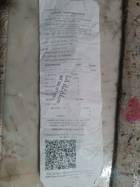
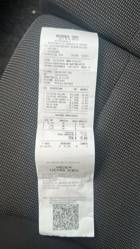
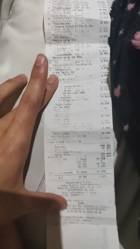
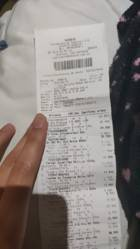
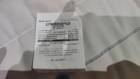
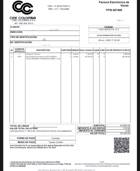
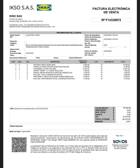
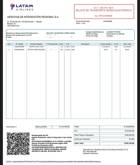
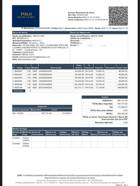
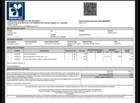
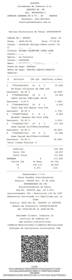
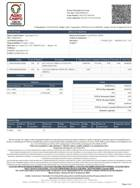
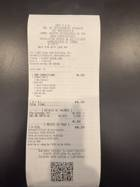
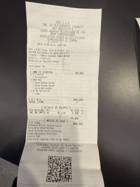
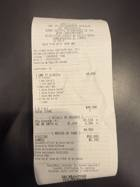
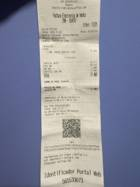
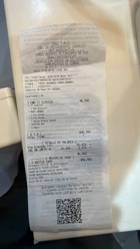
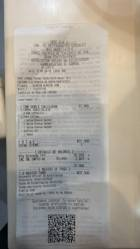
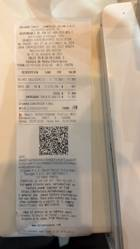
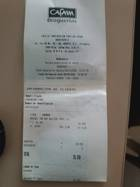
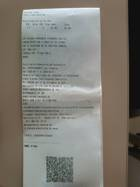
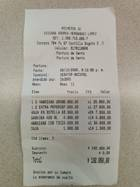
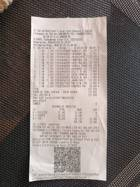
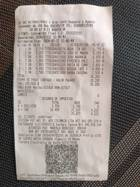
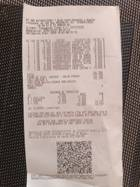
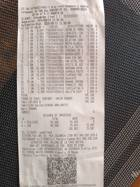
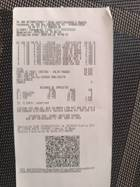
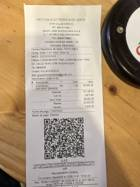
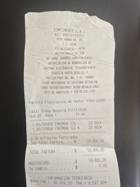
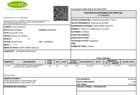
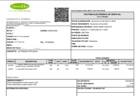
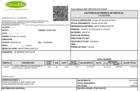
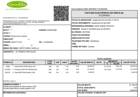
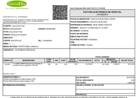
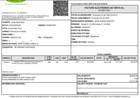
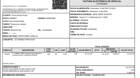
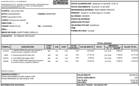
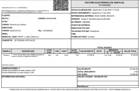
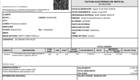
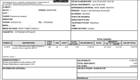
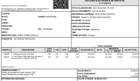
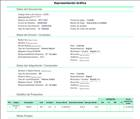
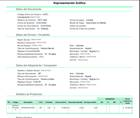
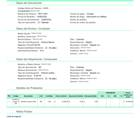
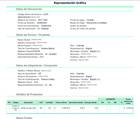
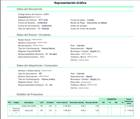
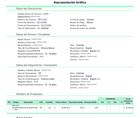
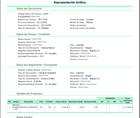
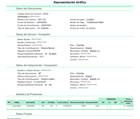
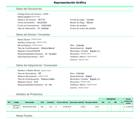
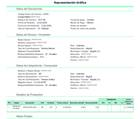
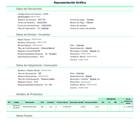
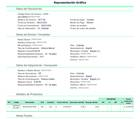
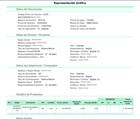
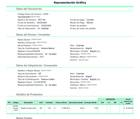
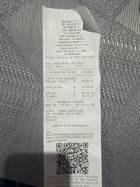
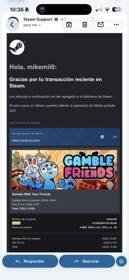
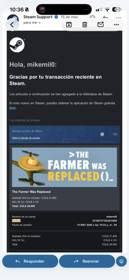
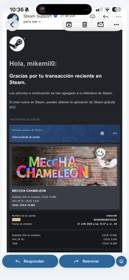
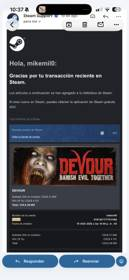
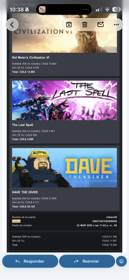
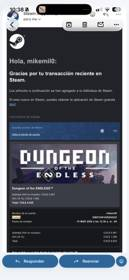
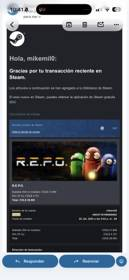
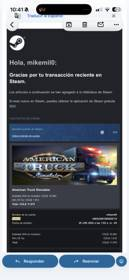
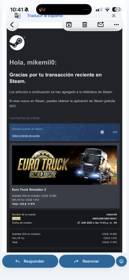
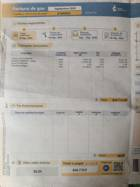
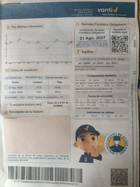
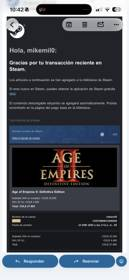
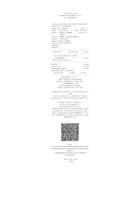
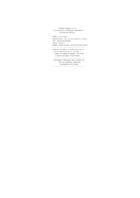
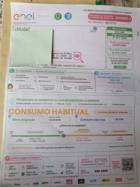
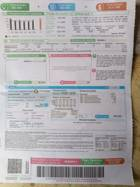
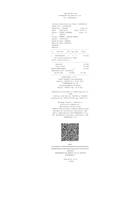
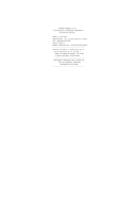
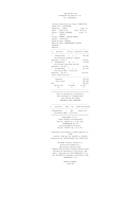
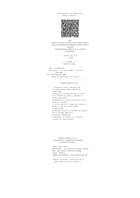
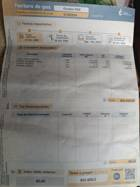
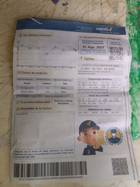
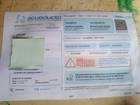
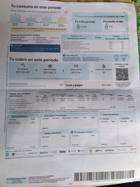
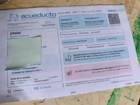
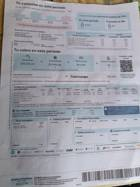
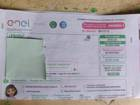
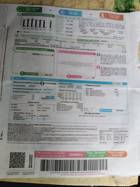
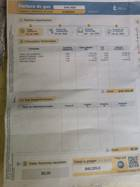
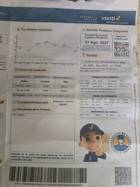
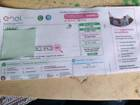
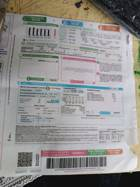
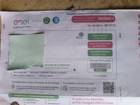
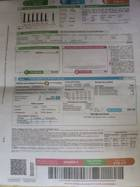
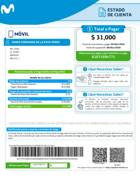
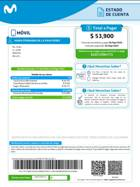
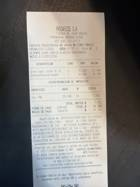
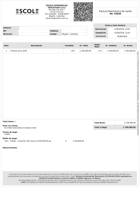
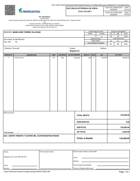
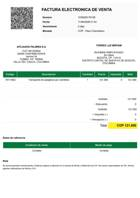
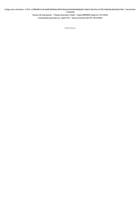
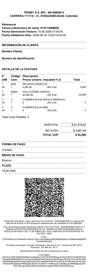
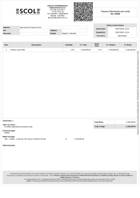
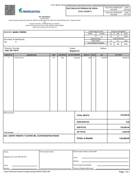
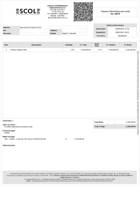
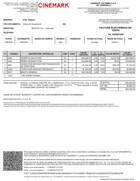
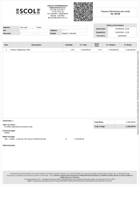
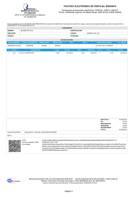
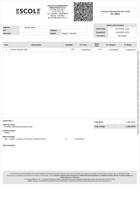
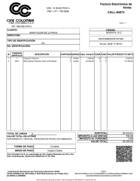
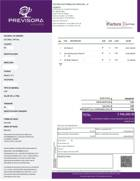
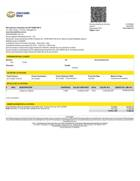
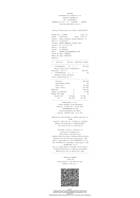
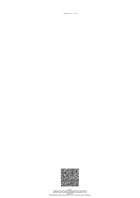
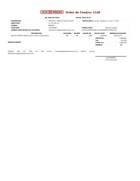
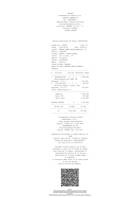
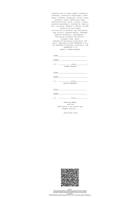
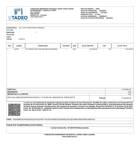
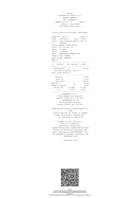
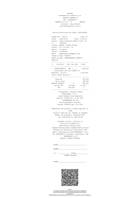
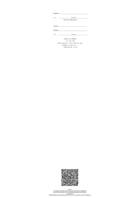
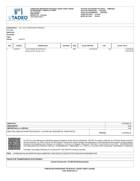
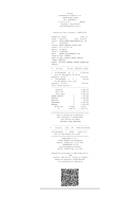
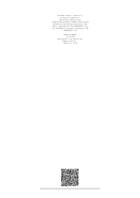
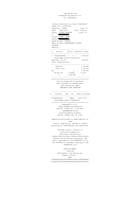
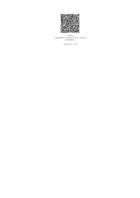
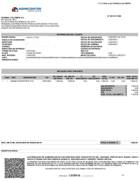
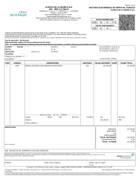
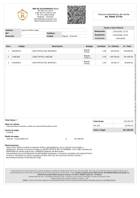
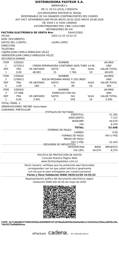
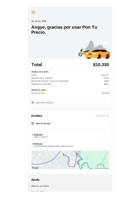
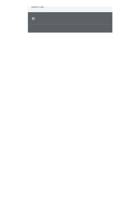
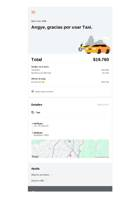
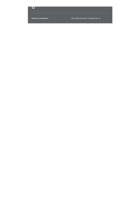
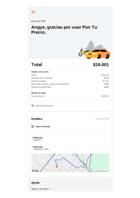
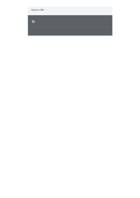
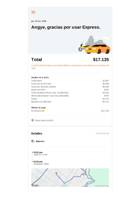
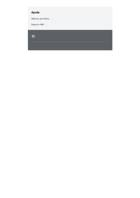
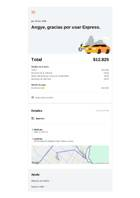
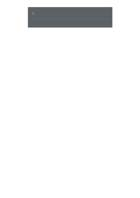
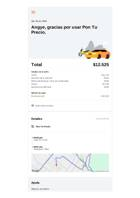
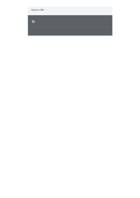
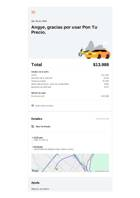
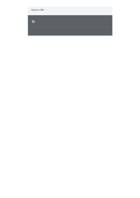
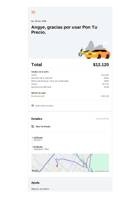
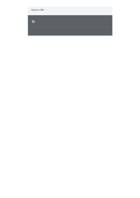
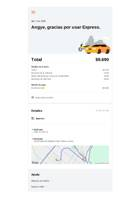
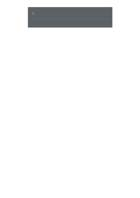
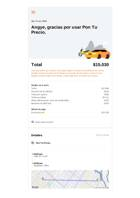
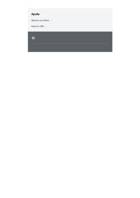
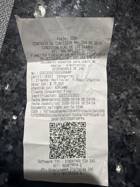
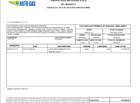
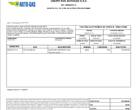
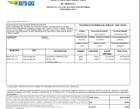
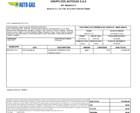
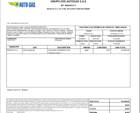
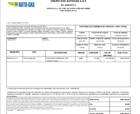
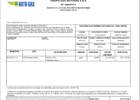
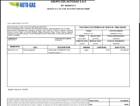
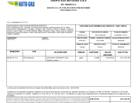
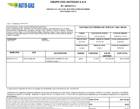
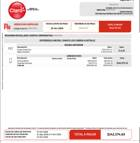
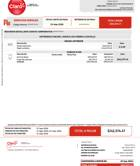
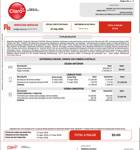
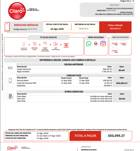
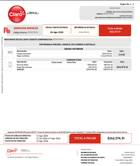
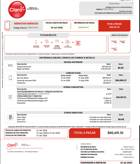
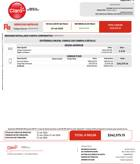
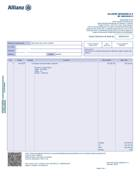
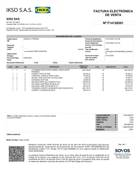
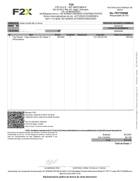
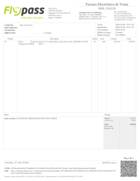
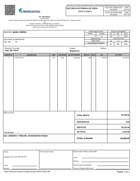
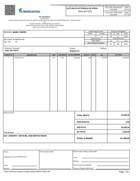
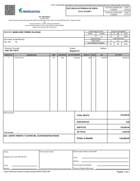
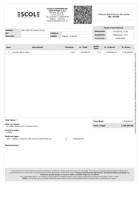
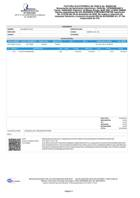


Facturas por categoría:
categoria
Supermercado                 32
Transporte                   26
Servicios                    18
Entretenimiento              17
Restaurantes y domicilios    12
Otros                        11
Salud                        11
Educación                     8
Ropa y accesorios             4
Hogar                         4

Resumen del tamaño de las imágenes:
Total de imágenes: 173
Ancho (px): mínimo 409, máximo 4.000, promedio 1.763
Alto (px): mínimo 750, máximo 4.032, promedio 2.262
Píxeles totales: mínimo 643.536, máximo 12.192.768, promedio 4.714.383
Peso promedio: 0,66 MB
Tamaños distintos: 65

Imágenes de baja resolución (lado largo menor a 1200 px): 37 de 173
    factura_005_1.jpg
    factura_006_1.jpg
    factura_007_1.jpg
    factura_008_1.jpg
    factura_009_1.jpg
    factura_028_1.jpeg
    factura_031_1.jpeg
    factura_032_1.jpeg
    factura_033_1.jpeg
    factura_040_1.png
    factura_041_1.png
    factura_042_1.png
    factura_043_1.png
    f

In [ ]:
# Tabla con miniaturas de las fotos
def miniatura(nombre, ancho=140):
    im = Image.open(os.path.join("dataset/imagenes", nombre)).convert("RGB")
    im.thumbnail((ancho, ancho * 2))
    b = io.BytesIO()
    im.save(b, "JPEG", quality=70)
    return "data:image/jpeg;base64," + base64.b64encode(b.getvalue()).decode()

def celda_foto(txt):
    partes = []
    for nombre in txt.split(";"):
        try:
            partes.append(f'<div style="display:inline-block;text-align:center;font-size:11px;margin:2px">'
                          f'<img src="{miniatura(nombre)}" style="border-radius:6px"><br>{nombre}</div>')
        except Exception:
            partes.append(nombre)
    return "".join(partes)

estilo = ("<style>.t{border-collapse:collapse;font-family:sans-serif;font-size:14px;color:#11201C;background:#fff}"
          ".t th{background:#0B6B57;color:#fff;padding:8px 12px;text-align:left}"
          ".t td{border-bottom:1px solid #ddd;padding:8px 12px;vertical-align:middle}"
          ".t tr:nth-child(even){background:#f3f6f5}</style>")
html = estilo + "<table class='t'><tr><th>Foto</th><th>Monto (COP)</th><th>Fecha</th><th>Categoría</th><th>Motivo</th><th>Tamaño de la imagen</th></tr>"
def miles(n):
    return f"{int(n):,}".replace(",", ".")

def celda_info(txt):
    bloques = []
    for nombre in txt.split(";"):
        d = info_por_archivo[nombre]
        peso = d["peso_kb"] / 1024
        peso_txt = f"{peso:,.1f} MB".replace(".", ",") if peso >= 1 else f"{d['peso_kb']:,.0f} KB"
        bloques.append(f"<b>{miles(d['ancho_px'])} × {miles(d['alto_px'])} px</b><br>"
                       f"{miles(d['pixeles_totales'])} píxeles<br>"
                       f"{miles(d['valores_totales'])} valores ({d['canales']} canales)<br>{peso_txt}"
                       + ("<br><span style='color:#B3261E;font-weight:bold'>BAJA RESOLUCIÓN</span>"
                          if d["baja_resolucion"] else ""))
    return "<br><br>".join(bloques)

for _, r in tabla.iterrows():
    monto = (f"$ {r.monto_cop:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")
             if pd.notna(r.monto_cop) else "sin dato")
    html += (f"<tr><td>{celda_foto(r.foto)}</td><td style='text-align:right'>{monto}</td>"
             f"<td>{r.fecha or 'sin dato'}</td><td>{r.categoria}</td><td>{r.motivo}</td>"
             f"<td style='font-size:12px;white-space:nowrap'>{celda_info(r.foto)}</td></tr>")
html += "</table>"
display(HTML(html))

print("\nFacturas por categoría:")
print(tabla["categoria"].value_counts().to_string())

print("\nResumen del tamaño de las imágenes:")
print(f"Total de imágenes: {len(info)}")
for c, nombre in [("ancho_px", "Ancho (px)"), ("alto_px", "Alto (px)"), ("pixeles_totales", "Píxeles totales")]:
    print(f"{nombre}: mínimo {miles(info[c].min())}, máximo {miles(info[c].max())}, promedio {miles(info[c].mean())}")
print(f"Peso promedio: {info['peso_kb'].mean() / 1024:,.2f} MB".replace(".", ","))
distintos = info[["ancho_px", "alto_px"]].drop_duplicates().shape[0]
print(f"Tamaños distintos: {distintos}")
bajas = info[info["baja_resolucion"]]
print(f"\nImágenes de baja resolución (lado largo menor a 1200 px): {len(bajas)} de {len(info)}")
for a in bajas["archivo"]:
    print("   ", a)

In [ ]:
# Guardar el CSV y descargar todo (CSV + carpeta de imágenes) en un zip
tabla.to_csv("dataset/facturas.csv", index=False, encoding="utf-8")
info.to_csv("dataset/info_imagenes.csv", index=False, encoding="utf-8")
shutil.make_archive("dataset_facturas", "zip", "dataset")
files.download("dataset_facturas.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>